# main: run the whole project in order

**Purpose.** One entry point that runs every step of the project top to bottom, so the results can be rebuilt with
*Restart, Run All* on this notebook only.

**Input.** Nothing beyond the repository and internet access for the first run (notebook 01 downloads the SEC and
FRED data; it needs `sec_user_agent.txt` in the repository root or the environment variable `SEC_USER_AGENT`, see
README).

**Output.** Everything the step notebooks write: `data/processed/`, `output/tables/`, `output/figures/`.

**Steps.**
1. `01_preprocess.ipynb`: working dataset of new BDC loans (about 25 minutes on a laptop, longer on the first run).
2. `02_estimate.ipynb`: model horse race on the validation folds (not written yet).
3. `03_evaluate.ipynb`: final evaluation on the test quarters, used once (not written yet).

## Step 1: preprocessing

project folder: DSF_Project
2022q4_bdc.zip     11.9
2023q1_bdc.zip     16.7
2023q2_bdc.zip     20.4
2023q3_bdc.zip     21.9
2023q4_bdc.zip     23.4
2024q1_bdc.zip     30.6
2024q2_bdc.zip     24.1
2024q3_bdc.zip     25.8
2024q4_bdc.zip     27.5
2025q1_bdc.zip     36.9
2025q2_bdc.zip     29.7
2025q3_bdc.zip     31.7
2025q4_bdc.zip     34.5
2026_01_bdc.zip     0.9
2026_02_bdc.zip    16.0
2026_03_bdc.zip    29.0
2026_04_bdc.zip     1.1
2026_05_bdc.zip    41.0
2026_06_bdc.zip     0.1
2026_07_bdc.zip     2.5
2026_08_bdc.zip    75.9
2026_09_bdc.zip     0.4
2026_10_bdc.zip     1.8


rows: 2035844  filings (adsh): 2310  BDCs (cik): 204


source_file
2022q4_bdc.zip      48
2023q1_bdc.zip      62
2023q2_bdc.zip     124
2023q3_bdc.zip     135
2023q4_bdc.zip     139
2024q1_bdc.zip     140
2024q2_bdc.zip     151
2024q3_bdc.zip     154
2024q4_bdc.zip     156
2025q1_bdc.zip     160
2025q2_bdc.zip     166
2025q3_bdc.zip     165
2025q4_bdc.zip     179
2026_01_bdc.zip      2
2026_02_bdc.zip     52
2026_03_bdc.zip    119
2026_04_bdc.zip      4
2026_05_bdc.zip    173
2026_07_bdc.zip      6
2026_08_bdc.zip    169
2026_09_bdc.zip      2
2026_10_bdc.zip      4


period-end months: {2: 1237, 3: 277813, 5: 1847, 6: 290617, 7: 215, 8: 2441, 9: 245044, 11: 1576, 12: 251826}


BDC-quarters with more than one filing: 12 (kept the latest filing)
         bdcs  filings   rows
quarter                      
2022Q3     49       49  31027
2022Q4     65       65  29841
2023Q1    123      123  47675
2023Q2    134      134  49342
2023Q3    140      140  53639
2023Q4    143      143  55655
2024Q1    149      149  59650
2024Q2    154      154  63475
2024Q3    158      158  68507
2024Q4    160      160  71487
2025Q1    165      165  75627
2025Q2    165      165  80294
2025Q3    167      167  87288
2025Q4    173      173  93515
2026Q1    174      174  96098
2026Q2    175      175  99257


BDCs: 204  families: 103  families with >1 BDC: 45
family
AG Twin Brook                                                                  [AG TWIN BROOK BDC, INC., TPG TWIN BROOK CAPITAL INCOME FUND]
AllianceBernstein                                                                [AB PRIVATE CREDIT INVESTORS CORP, AB PRIVATE LENDING FUND]
Antares                                   [ANTARES PRIVATE CREDIT FUND, ANTARES STRATEGIC CREDIT FUND, ANTARES STRATEGIC CREDIT FUND II LLC]
Apollo               [APOLLO DEBT SOLUTIONS BDC, APOLLO ORIGINATION II (LEVERED) CAPITAL TRUST, APOLLO ORIGINATION II (UL) CAPITAL TRUST,...
Ares                                                          [ARES CAPITAL CORP, ARES CORE INFRASTRUCTURE FUND, ARES STRATEGIC INCOME FUND]
Audax                                                                                [AUDAX CREDIT BDC INC., AUDAX PRIVATE CREDIT FUND, LLC]
BC Partners                                                       [BC PARTNERS LENDING CORP, BCP

... (18 outputs left out)

            baa_spread_prev baa_spread_prev_date  sofr_prev sofr_prev_date  hy_oas_prev hy_oas_prev_date  mkt_spread_t2_all  mkt_n_t2_all  mkt_late_t2_all  mkt_spread_t2_core  mkt_n_t2_core  mkt_late_t2_core
2023-04-01             2.11           2023-03-31       4.87     2023-03-31          NaN              NaT               6.50        112.00             0.00                 NaN          12.00              0.00
2023-07-01             1.88           2023-06-30       5.09     2023-06-30          NaN              NaT               6.75         94.00             0.00                 NaN          14.00              0.00
2023-10-01             1.78           2023-09-29       5.31     2023-09-29          NaN              NaT               6.00        264.00             0.00                6.75          41.00              0.00
2024-01-01             1.61           2023-12-29       5.38     2023-12-29         3.39       2023-12-31               5.25        382.00             0.00              

variant incl. refinancings: (2185, 56)
core: (1747, 54)  all-BDC: (7303, 54)
       loans   first    last
split                       
test     604  2025Q3  2026Q2
train   1143  2023Q2  2025Q2
       spread_pp  tenor_years  log_principal  baa_spread_prev  sofr_prev  mkt_spread_t2_all
count    1747.00      1747.00        1747.00          1747.00    1747.00            1747.00
mean        4.83         6.32          16.13             1.66       4.69               5.10
std         1.23         0.85           1.47             0.14       0.56               0.54
min         1.75         4.06          11.51             1.42       3.68               4.50
25%         4.25         5.58          15.20             1.55       4.41               4.75
50%         5.00         6.23          16.17             1.67       4.49               5.00
75%         5.50         7.12          17.11             1.76       5.33               5.25
max         9.50         7.50          20.48             2.11       5.3

                                      1_candidates  2_complete_prev_q  3_not_held_before  4_acq_rule  5_final_core
family                                                                                                            
Apollo                                        7390               7136                646         646           338
Goldman Sachs                                 7626               7404                596         596           193
BlackRock                                     4073               3877                291         291           130
Antares                                       3766               3489                253         253           120
First Eagle                                   1156               1130                192         189            94
Bain Capital                                  2658               2555                219         219            76
Jefferies                                     1322               1280           

                        count   25%   50%   75%
sector                                         
Industrials             518.0  4.50  5.00  5.50
Information Technology  271.0  4.50  5.00  5.75
Health Care             269.0  4.50  5.00  5.50
Consumer Discretionary  239.0  4.25  5.00  5.75
Financials              144.0  3.25  4.50  5.25
Consumer Staples         83.0  4.38  5.00  5.75
Materials                75.0  3.50  4.75  5.25
Communication Services   74.0  3.50  4.75  6.00
Energy                   46.0  2.81  3.88  5.69
Utilities                17.0  3.00  3.50  5.25
Real Estate              11.0  5.00  5.50  5.75
                                count   50%
family                                     
Apollo                          338.0  4.75
Goldman Sachs                   193.0  4.75
BlackRock                       130.0  4.25
Antares                         120.0  4.50
First Eagle                      94.0  3.62
Bain Capital                     76.0  5.25
Jefferies               

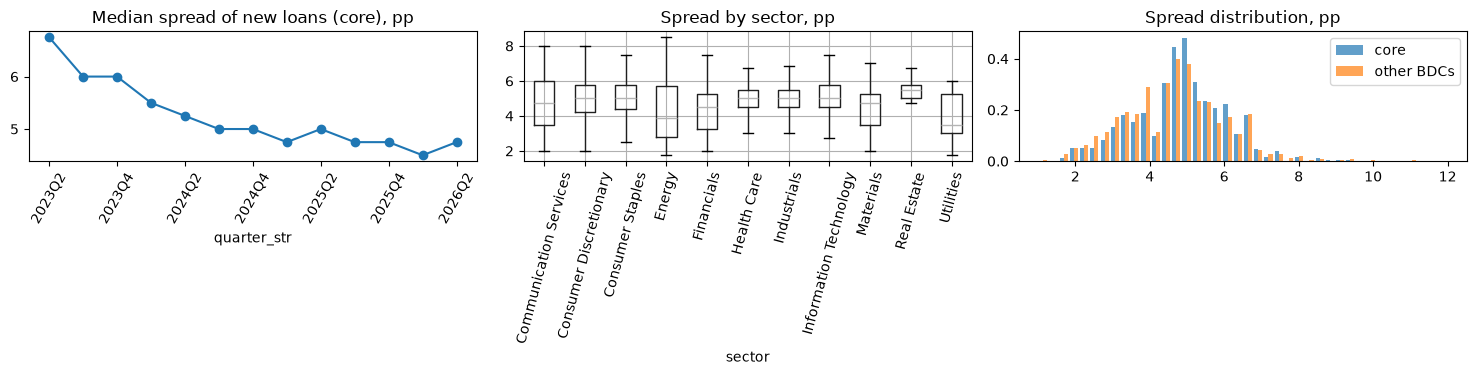

                         feature                                                           value fixed by                            check
                     tenor_years                              computed from quarter_start (contract term)                  by construction
                   log_principal held principal at the reporting date (approximation of the planned hold)                  by construction
sector, lien, instrument, family                  contract characteristics, fixed when the deal is signed                  by construction
      baa_spread_prev, sofr_prev                                    FRED value dated before quarter_start                             True
               mkt_spread_t2_all                          loans of quarter t-2 filed before quarter_start asserted below for every quarter
t-2 market median and FRED dates checked for 13 quarters


checked loans whose loan_id changed since the check (family re-mapping): 5
hand-checked loans: 50  families: 29  still in the final sample: 37
found_in_filing  matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
spread_ok        matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
maturity_ok      matches: 49 of 50 (others: value tagged in XBRL but not printed next to the name)
principal_ok     matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
industry_ok      matches: 48 of 50 (others: value tagged in XBRL but not printed next to the name)


Patrick's hand-checked loans: 50  in our final sample: 27  classes there: {'a': 26, 'b': 1}  classes of the others: {'a': 15, 'b': 8}
loans checked by both: 0  same class: 0
                                    sample class  n  share  ci_low  ci_high
                          all checked (50)     a 35  0.700   0.562    0.809
                          all checked (50)     b 14  0.280   0.175    0.417
                          all checked (50)     c  1  0.020   0.004    0.105
                      in final sample (37)     a 32  0.865   0.720    0.941
                      in final sample (37)     b  4  0.108   0.043    0.247
                      in final sample (37)     c  1  0.027   0.005    0.138
             Patrick, in final sample (27)     a 26  0.963   0.817    0.993
             Patrick, in final sample (27)     b  1  0.037   0.007    0.183
             Patrick, in final sample (27)     c  0  0.000   0.000    0.125
both checks combined, in final sample (64)     a 58  0.906   0.810

                            count   25%   50%   75%
refi_of_existing_borrower                          
False                      1795.0  4.25  5.00  5.50
True                        390.0  3.25  4.31  5.25


fold 0: train  304 loans up to 2024Q1, validate 181 loans in 2024Q3
fold 1: train  457 loans up to 2024Q2, validate 206 loans in 2024Q4
fold 2: train  638 loans up to 2024Q3, validate 156 loans in 2025Q1
fold 3: train  842 loans up to 2024Q4, validate 143 loans in 2025Q2
final: train 1000 loans up to 2025Q1 | test 604


design matrix of the training data: (1143, 43)
test quarter 2025Q3: train 1000 loans up to 2025Q1, test 174 loans
test quarter 2025Q4: train 1143 loans up to 2025Q2, test 152 loans
test quarter 2026Q1: train 1317 loans up to 2025Q3, test 151 loans
test quarter 2026Q2: train 1469 loans up to 2025Q4, test 127 loans
                                                                       item  value  ci_low  ci_high     n         note
                                                          loans (loans.csv)   1747     NaN      NaN   NaN             
                                                              first quarter 2023Q2     NaN      NaN   NaN             
                                                               last quarter 2026Q2     NaN      NaN   NaN             
                                             train loans (2023Q2 to 2025Q2)   1143     NaN      NaN   NaN             
                                              test loans (2025Q3 to 2026Q2)    604     NaN

In [1]:
%run 01_preprocess.ipynb

## Step 2: estimation (placeholder)

In [2]:
# %run 02_estimate.ipynb

## Step 3: evaluation on the test quarters (placeholder)

In [3]:
# %run 03_evaluate.ipynb

## Check

In [4]:
import pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
h = pd.read_csv(ROOT / "output" / "tables" / "headline_numbers.csv")
print(h[["item", "value"]].head(8).to_string(index=False))
# Check: the main output exists and has the number of rows reported in the headline table.
assert len(pd.read_csv(ROOT / "data" / "processed" / "loans.csv")) == int(h.set_index("item").loc["loans (loans.csv)", "value"])

                          item  value
             loans (loans.csv)   1747
                 first quarter 2023Q2
                  last quarter 2026Q2
train loans (2023Q2 to 2025Q2)   1143
 test loans (2025Q3 to 2026Q2)    604
             test loans 2025Q3    174
             test loans 2025Q4    152
             test loans 2026Q1    151
